# Example 7.1 — Drug-likeness radar: the DPP-4 inhibitors

A reproducible record of an AI-assisted BindingDB analysis: each prompt, the BindingDB tool calls that answered it with their recorded results, the answer, and its figures. Run all cells to show the recorded results, or rerun every call on your own copy of the database and check each result against the recorded one.

- **Date:** 2026-11-23
- **Model:** claude-sonnet-5-5
- **Data:** BindingDB release **202611** (`BDB-mySQL_All_202611_dmp.zip`, SHA-256 `daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381`)
- **Database build:** 2026-11-21T01:08:15+00:00, DuckDB 1.5.6
- **Derived data:** standard InChIKeys computed from SMILES by RDKit 2026.03.6; compound_property computed from SMILES (largest fragment) by RDKit 2026.03.6
- **Server:** mcp-bindingdb v0.1.17, commit [`79dae5d22c0f`](https://github.com/sbl-sdsc/mcp-bindingdb/commit/79dae5d22c0f15b8ded9b49adc8b105f0463703a)
- **Software:** python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5
- **Notebook generated:** 2026-11-24T04:56:12Z
- **Contents:** 1 exchange · 14 tool calls · 2 figures · 1 code cell

### How to run

Keep the notebook in its folder, which holds everything it needs: `requirements.txt` (mcp-bindingdb at its commit and the versions of the packages it needs), the recorded results in `data/`, the figures in `figures/` and the analysis code the notebook imports (`plot_gliptin_radar.py`). With [uv](https://docs.astral.sh/uv/), from that folder (replace the path with yours):

```bash
cd /path/to/7.1-drug-likeness-radar-notebook
uv run --no-project --with-requirements requirements.txt --with jupyterlab jupyter lab 7.1-drug-likeness-radar-notebook.ipynb
```

then choose Run → Run All Cells. The first start installs the packages, which takes a minute or two; the cells show the recorded results, so no database is needed. Without uv: `pip install -r requirements.txt jupyterlab`, then `jupyter lab 7.1-drug-likeness-radar-notebook.ipynb` in the folder.

### How to rerun the calls

To rerun every BindingDB call on your own copy of release 202611 and check each result against the recorded one, set `RERUN = True` in the setup cell and run all cells, or rerun the notebook without opening Jupyter, writing a copy with the new results:

```bash
cd /path/to/7.1-drug-likeness-radar-notebook
BINDINGDB_RERUN=1 uv run --no-project --with-requirements requirements.txt --with nbconvert jupyter nbconvert --to notebook --execute --output 7.1-drug-likeness-radar-notebook-rerun.ipynb 7.1-drug-likeness-radar-notebook.ipynb
```

A rerun needs the database: the one `BINDINGDB_DUCKDB=/path/to/bindingdb_202611.duckdb` names (put it before `uv run`), else the newest one mcp-bindingdb built on this computer, for example for Claude Desktop. With neither, the first rerun builds one, which takes about half an hour and 2.4 GB. To build exactly release 202611, with a clone of mcp-bindingdb:

```bash
git clone https://github.com/sbl-sdsc/mcp-bindingdb.git
cd mcp-bindingdb
git checkout 79dae5d22c0f15b8ded9b49adc8b105f0463703a
scripts/build_duckdb.sh --release 202611
```

The setup cell checks the database's release and source checksum against the recorded ones.

Run as it is, each call cell shows its recorded result, read from `data/` and checked against the SHA-256 digest recorded in the cell. Rerun, it shows the new result with ✅ when it matches the recorded one (floats to 10 significant digits, ids of viewers and files left out). Calls to PubChem, RCSB or PDBe depend on those services and may differ. The prose answers are the model's and are not recomputed. Code cells hold the analysis code the model wrote; they run as written (reading the results with `replay.result(n)`, the result of Call n) and draw their figures again, which are not compared.

In [ ]:
# Shows the results recorded during the session (data/), so the notebook runs without a database. Set
# RERUN = True (or start Jupyter with BINDINGDB_RERUN=1) to rerun every BindingDB call on a local copy of
# the database instead and check it against its recorded result: see 'How to rerun the calls' above.
from mcp_bindingdb.notebook import Replay

RERUN = False
replay = Replay(release='202611', source_zip_sha256='daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381', rerun=RERUN)

Recorded with BindingDB release 202611, mcp-bindingdb v0.1.17 (commit 79dae5d22c0f)
python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5


## Exchange 1

**👤 User**

How drug-like are the DPP-4 inhibitors, the gliptins? Compare their properties in radar plots, and show their structures with how potent and selective they are.

In [ ]:
# Call 1 · chemical_name_to_smiles · ran 2026-11-24 04:56:10 UTC
await replay.call(1, 'chemical_name_to_smiles', {'name': 'sitagliptin'},
                  sha256='e14258eee2a2a412ea13d054e210ab1613237eed3cda66927f018fede0c9f2d2')

**Call 1** · `chemical_name_to_smiles` · recorded result · sha256 `e14258eee2a2…` · uses PubChem, whose answers can change

| name | smiles |
| --- | --- |
| sitagliptin | N\[C@@H\](CC(=O)N1CCn2c(C1)nnc2C(F)(F)F)Cc1cc(F)c(F)cc1F \|r\| |

```json
{
  "query": "sitagliptin",
  "resolved": true,
  "source": "bindingdb",
  "smiles": "N[C@@H](CC(=O)N1CCn2c(C1)nnc2C(F)(F)F)Cc1cc(F)c(F)cc1F |r|",
  "inchi_key": "MFFMDFFZMYYVKS-SECBINFHSA-N",
  "monomerid": 11162,
  "ambiguous": false
}
```

**candidates**: 2 rows

| monomerid | bdbm_id | name | inchi_key | smiles | n_activities |
| --- | --- | --- | --- | --- | --- |
| 11162 | BDBM11162 | Sitagliptin | MFFMDFFZMYYVKS-SECBINFHSA-N | N\[C@@H\](CC(=O)N1CCn2c(C1)nnc2C(F)(F)F)Cc1cc(F)c(F)cc1F \|r\| | 188 |
| 13513 | BDBM13513 | Sitagliptin | MFFMDFFZMYYVKS-SECBINFHSA-N | N\[C@@H\](CC(=O)N1CCn2c(C1)nnc2C(F)(F)F)Cc3cc(F)c(F)cc3F | 2 |

**sources_tried**: 1 row

| source | status |
| --- | --- |
| bindingdb | found |


In [ ]:
# Call 2 · chemical_name_to_smiles · ran 2026-11-24 04:56:11 UTC
await replay.call(2, 'chemical_name_to_smiles', {'name': 'vildagliptin'},
                  sha256='2d711dfadf32a4da0e779855820f1318aff2fb928031552bf7710488bb59b316')

**Call 2** · `chemical_name_to_smiles` · recorded result · sha256 `2d711dfadf32…` · uses PubChem, whose answers can change

| name | smiles |
| --- | --- |
| vildagliptin | N#C\[C@@H\]1CCCN1C(=O)CNC12CC3CC(CC(O)(C3)C1)C2 |

```json
{
  "query": "vildagliptin",
  "resolved": true,
  "source": "pubchem",
  "smiles": "N#C[C@@H]1CCCN1C(=O)CNC12CC3CC(CC(O)(C3)C1)C2",
  "inchi_key": "SYOKIDBDQMKNDQ-XWTIBIIYSA-N",
  "pubchem_name": "Vildagliptin",
  "pubchem_cid": 6918537
}
```

**bindingdb_matches**: 5 rows

| monomerid | bdbm_id | name | inchi_key | smiles | n_activities | exact_match |
| --- | --- | --- | --- | --- | --- | --- |
| 11695 | BDBM11695 | NVP-LAF237 | SYOKIDBDQMKNDQ-XWTIBIIYSA-N | N#C\[C@@H\]1CCCN1C(=O)CNC12CC3CC(CC(O)(C3)C1)C2 | 121 | True |
| 50129889 | BDBM50129889 | 1-\[2-(3-Hydroxy-adamantan-1-ylamino)-acetyl\]-pyrrolidine-2-carbonitrile | SYOKIDBDQMKNDQ-IGEWIKJLSA-N | N#C\[C@@H\]1CCCN1C(=O)CNC12C\[C@H\]3C\[C@@H\](C1)C\[C@\](O)(C3)C2 | 5 | False |
| 123776 | BDBM123776 | (2S)-1-(2-{\[(1r,3s,5R,7S)-3-hydroxyadamantan-1- yl\]amino}acetyl)pyrrolidine-2-carbonitrile (11) | SYOKIDBDQMKNDQ-NHMCJKAESA-N | N#C\[C@@H\]1CCCN1C(=O)CN\[C@@\]12C\[C@@H\]3C\[C@@H\](C\[C@@\](O)(C3)C1)C2 | 1 | False |
| 126821 | BDBM126821 | US8785477, Vildagliptin | SYOKIDBDQMKNDQ-UHFFFAOYSA-N | N#CC1CCCN1C(=O)CNC12CC3CC(CC(O)(C3)C1)C2 | 1 | False |
| 664702 | BDBM664702 | (2S)-1-(((1S,3R,5S)-3-hydroxyadamantan-1- yl)glycyl)pyrrolidine-2-carbonitrile (vildagliptin) | SYOKIDBDQMKNDQ-MLIKTYCQSA-N | N#C\[C@@H\]1CCCN1C(=O)CNC12CC3C\[C@@H\](C1)C\[C@@\](O)(C3)C2 | 1 | False |

**sources_tried**: 3 rows

| source | status |
| --- | --- |
| bindingdb | not found |
| opsin | not found |
| pubchem | found |


In [ ]:
# Call 3 · chemical_name_to_smiles · ran 2026-11-24 04:56:11 UTC
await replay.call(3, 'chemical_name_to_smiles', {'name': 'saxagliptin'},
                  sha256='a72d6033a74f020dd4aebadd273e06948fa17e5bee92016a77c89316b9984f12')

**Call 3** · `chemical_name_to_smiles` · recorded result · sha256 `a72d6033a74f…` · uses PubChem, whose answers can change

| name | smiles |
| --- | --- |
| saxagliptin | N#C\[C@@H\]1C\[C@@H\]2C\[C@@H\]2N1C(=O)\[C@@H\](N)C12CC3CC(CC(O)(C3)C1)C2 |

```json
{
  "query": "saxagliptin",
  "resolved": true,
  "source": "bindingdb",
  "smiles": "N#C[C@@H]1C[C@@H]2C[C@@H]2N1C(=O)[C@@H](N)C12CC3CC(CC(O)(C3)C1)C2",
  "inchi_key": "QGJUIPDUBHWZPV-SGTAVMJGSA-N",
  "monomerid": 50225074,
  "ambiguous": false
}
```

**candidates**: 2 rows

| monomerid | bdbm_id | name | inchi_key | smiles | n_activities |
| --- | --- | --- | --- | --- | --- |
| 50225074 | BDBM50225074 | SAXAGLIPTIN | QGJUIPDUBHWZPV-SGTAVMJGSA-N | N#C\[C@@H\]1C\[C@@H\]2C\[C@@H\]2N1C(=O)\[C@@H\](N)C12CC3CC(CC(O)(C3)C1)C2 | 49 |
| 11542 | BDBM11542 | Saxagliptin | QGJUIPDUBHWZPV-SGTAVMJGSA-N | N#C\[C@@H\]1C\[C@@H\]2C\[C@@H\]2N1C(=O)\[C@@H\](N)C12CC3CC(CC(O)(C3)C1)C2 | 6 |

**sources_tried**: 1 row

| source | status |
| --- | --- |
| bindingdb | found |


In [ ]:
# Call 4 · chemical_name_to_smiles · ran 2026-11-24 04:56:11 UTC
await replay.call(4, 'chemical_name_to_smiles', {'name': 'alogliptin'},
                  sha256='a79728703088bbb1fd0b7de5ae9fe62579fd74be6afa0de599404f0b28cfb2e5')

**Call 4** · `chemical_name_to_smiles` · recorded result · sha256 `a79728703088…` · uses PubChem, whose answers can change

| name | smiles |
| --- | --- |
| alogliptin | Cn1c(=O)cc(N2CCC\[C@@H\](N)C2)n(Cc2ccccc2C#N)c1=O \|r\| |

```json
{
  "query": "alogliptin",
  "resolved": true,
  "source": "bindingdb",
  "smiles": "Cn1c(=O)cc(N2CCC[C@@H](N)C2)n(Cc2ccccc2C#N)c1=O |r|",
  "inchi_key": "ZSBOMTDTBDDKMP-OAHLLOKOSA-N",
  "monomerid": 16285,
  "ambiguous": false
}
```

**candidates**: 1 row

| monomerid | bdbm_id | name | inchi_key | smiles | n_activities |
| --- | --- | --- | --- | --- | --- |
| 16285 | BDBM16285 | Alogliptin | ZSBOMTDTBDDKMP-OAHLLOKOSA-N | Cn1c(=O)cc(N2CCC\[C@@H\](N)C2)n(Cc2ccccc2C#N)c1=O \|r\| | 70 |

**sources_tried**: 1 row

| source | status |
| --- | --- |
| bindingdb | found |


In [ ]:
# Call 5 · chemical_name_to_smiles · ran 2026-11-24 04:56:11 UTC
await replay.call(5, 'chemical_name_to_smiles', {'name': 'linagliptin'},
                  sha256='b237353a08edee787b0aa1d7398ec295a2f54554b7e899c70a35fadabcbaee44')

**Call 5** · `chemical_name_to_smiles` · recorded result · sha256 `b237353a08ed…` · uses PubChem, whose answers can change

| name | smiles |
| --- | --- |
| linagliptin | CC#CCn1c(nc2n(C)c(=O)n(Cc3nc(C)c4ccccc4n3)c(=O)c12)N1CCC\[C@@H\](N)C1 |

```json
{
  "query": "linagliptin",
  "resolved": true,
  "source": "bindingdb",
  "smiles": "CC#CCn1c(nc2n(C)c(=O)n(Cc3nc(C)c4ccccc4n3)c(=O)c12)N1CCC[C@@H](N)C1",
  "inchi_key": "LTXREWYXXSTFRX-QGZVFWFLSA-N",
  "monomerid": 50228403,
  "ambiguous": false
}
```

**candidates**: 1 row

| monomerid | bdbm_id | name | inchi_key | smiles | n_activities |
| --- | --- | --- | --- | --- | --- |
| 50228403 | BDBM50228403 | LINAGLIPTIN | LTXREWYXXSTFRX-QGZVFWFLSA-N | CC#CCn1c(nc2n(C)c(=O)n(Cc3nc(C)c4ccccc4n3)c(=O)c12)N1CCC\[C@@H\](N)C1 | 62 |

**sources_tried**: 1 row

| source | status |
| --- | --- |
| bindingdb | found |


In [ ]:
# Call 6 · search_targets · ran 2026-11-24 04:56:11 UTC
await replay.call(6, 'search_targets', {'query': 'DPP4', 'limit': 6},
                  sha256='2c192d21f6f2a2cd35c31641d85de5125f658287417db98c6deb17182ff6ff59')

**Call 6** · `search_targets` · recorded result · sha256 `2c192d21f6f2…`

_6 rows, truncated at the limit_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 1234 | Dipeptidyl peptidase 4 | P27487 | P27487 | Homo sapiens | Enzyme | 6371 | 5246 | DPP4 |
| polymer | 1264 | Dipeptidyl peptidase 4 | P14740 | P14740 | Rattus norvegicus | Enzyme | 224 | 207 | Dpp4 |
| polymer | 1262 | Dipeptidyl peptidase 4 | P22411 | P22411 | Sus scrofa | Enzyme | 133 | 115 | DPP4 |
| polymer | 50002948 | Dipeptidyl peptidase 4 | P28843 | P28843 | Mus musculus | PROTEIN | 63 | 60 | Dpp4 |
| polymer | 7424 | Dipeptidyl peptidase 4 \[K6R,T557I\] | P27487 | P27487\[K6R,T557I\] | Homo sapiens | Protein | 32 | 32 | DPP4 |
| polymer | 50001013 | Dipeptidyl peptidase 4 | P81425 | P81425 | Bos taurus | PROTEIN | 5 | 5 | DPP4 |


In [ ]:
# Call 7 · search_targets · ran 2026-11-24 04:56:11 UTC
await replay.call(7, 'search_targets', {'query': 'DPP8', 'limit': 6},
                  sha256='7c18fa937aae12b049c1e401821aebd248e8282f72e9c5e0a942d269682d1466')

**Call 7** · `search_targets` · recorded result · sha256 `7c18fa937aae…`

_2 rows_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 1236 | Dipeptidyl peptidase 8 | Q6V1X1 | Q6V1X1 | Homo sapiens | Enzyme | 2342 | 2016 | DPP8 |
| complex | 336 | Dipeptidyl peptidase 8/9 |  |  |  | Protein | 77 | 35 | DPP8/9 |


In [ ]:
# Call 8 · search_targets · ran 2026-11-24 04:56:11 UTC
await replay.call(8, 'search_targets', {'query': 'DPP9', 'limit': 6},
                  sha256='6315fef7090b77aeee033e59a6aff4a15fd33b0ca063a1c00dbd8dff20e7372e')

**Call 8** · `search_targets` · recorded result · sha256 `6315fef7090b…`

_6 rows, truncated at the limit_

| target_kind | target_id | name | uniprot | uniprot_raw | organism | type | n_activities | n_compounds | matched_name |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| polymer | 1237 | Dipeptidyl peptidase 9 | Q86TI2 | Q86TI2 | Homo sapiens | Enzyme | 1821 | 1608 | DPP9 |
| polymer | 50007587 | Dipeptidyl peptidase 9 |  |  | Bos taurus | PROTEIN | 7 | 7 | DPP9 |
| polymer | 8998 | Dipeptidyl peptidase 9 \[Y277A\] | Q86TI2 | Q86TI2\[Y277A\] | Homo sapiens | Enzyme | 1 | 1 | DPP9 |
| polymer | 8999 | Dipeptidyl peptidase 9 \[V285A\] | Q86TI2 | Q86TI2\[V285A\] | Homo sapiens | Enzyme | 1 | 1 | DPP9 |
| polymer | 9000 | Dipeptidyl peptidase 9 \[E286A\] | Q86TI2 | Q86TI2\[E286A\] | Homo sapiens | Enzyme | 1 | 1 | DPP9 |
| polymer | 9001 | Dipeptidyl peptidase 9 \[I288A\] | Q86TI2 | Q86TI2\[I288A\] | Homo sapiens | Enzyme | 1 | 1 | DPP9 |


In [ ]:
# Call 9 · get_compound · ran 2026-11-24 04:56:12 UTC
await replay.call(9, 'get_compound', {'monomerid': 11162},
                  sha256='2577c87c9f2274686f30ee98098ee8736081a423d8d62a297929ba59e448a80e')

**Call 9** · `get_compound` · recorded result · sha256 `2577c87c9f22…`

| name | smiles |
| --- | --- |
| Sitagliptin | N\[C@@H\](CC(=O)N1CCn2c(C1)nnc2C(F)(F)F)Cc1cc(F)c(F)cc1F \|r\| |

```json
{
  "compound": {
    "monomerid": 11162,
    "bdbm_id": "BDBM11162",
    "name": "Sitagliptin",
    "inchi_key": "MFFMDFFZMYYVKS-SECBINFHSA-N",
    "smiles": "N[C@@H](CC(=O)N1CCn2c(C1)nnc2C(F)(F)F)Cc1cc(F)c(F)cc1F |r|",
    "formula": "C16H15F6N5O",
    "mol_weight": 407.12,
    "type": "Small organic molecule",
    "het_pdb": "",
    "n_pdb_ids_exact": 0,
    "n_activities": 188,
    "n_targets": 35,
    "inchi": "InChI=1/C16H15F6N5O/c17-10-6-12(19)11(18)4-8(10)3-9(23)5-14(28)26-1-2-27-13(7-26)24-25-15(27)16(20,21)22/h4,6,9H,1-3,5,7,23H2/t9-/s2",
    "pdb_ids_exact": "",
    "pdb_ids_sub": null
  },
  "synonyms": [
    "MK-0431",
    "Sitagliptin",
    "CHEMBL393336",
    "Sitagliptin (13)",
    "US10479798, Compound MK0431",
    "Triazolopiperazine Analogue 1",
    "(1R)-3-oxo-3-[3-(trifluoroethyl)-5,6-dihydro[1,2,4]triazolo[4,3-a]pyrazin-7(8H)-yl]-1-(2,4,5-trifluorobenzyl)propylamine",
    "(3R)-3-amino-1-[3-(trifluoromethyl)-5H,6H,7H,8H-[1,2,4]triazolo[3,4-a]pyrazin-7-yl]-4-(2,4,5-trifluorophenyl)butan-1-one hydrochloride"
  ],
  "properties": {
    "heavy_atoms": 28,
    "mw": 407.32,
    "clogp": 2.02,
    "tpsa": 77.04,
    "hbd": 2,
    "hba": 6,
    "rotatable_bonds": 4,
    "rings": 3,
    "aromatic_rings": 2,
    "fsp3": 0.438,
    "qed": 0.622,
    "ro5_violations": 0,
    "scaffold": "O=C(CCCc1ccccc1)N1CCn2cnnc2C1",
    "generic_scaffold": "CC(CCCC1CCCCC1)C1CCC2CCCC2C1",
    "pains": [],
    "brenk": [
      "halogenated_ring_1"
    ],
    "nih": []
  }
}
```

**top_targets**: 25 rows

| polymerid | complexid | target_name | uniprot_raw | organism | n_measurements | best_p_affinity | affinity_types | best_ligand_efficiency |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1234 |  | Dipeptidyl peptidase 4 | P27487 | Homo sapiens | 73 | 9.06 | IC50, Kd, Ki | 0.44 |
| 7424 |  | Dipeptidyl peptidase 4 \[K6R,T557I\] | P27487\[K6R,T557I\] | Homo sapiens | 1 | 7.96 | IC50 | 0.39 |
| 50002948 |  | Dipeptidyl peptidase 4 | P28843 | Mus musculus | 4 | 7.82 | IC50 | 0.38 |
| 1264 |  | Dipeptidyl peptidase 4 | P14740 | Rattus norvegicus | 1 | 7.48 | IC50 | 0.37 |
| 1236 |  | Dipeptidyl peptidase 8 | Q6V1X1 | Homo sapiens | 25 | 5.74 | IC50 | 0.28 |
| 1237 |  | Dipeptidyl peptidase 9 | Q86TI2 | Homo sapiens | 21 | 5.51 | IC50 | 0.27 |
| 5699 |  | Prolyl endopeptidase FAP | Q12884 | Homo sapiens | 11 | 5.23 | IC50 | 0.26 |
| 1192 |  | Carbonic anhydrase 1 | P00915 | Homo sapiens | 1 | 5 | Ki | 0.24 |
| 1193 |  | Carbonic anhydrase 2 | P00918 | Homo sapiens | 1 | 5 | Ki | 0.24 |
| 1228 |  | Carbonic anhydrase 5A, mitochondrial | P35218 | Homo sapiens | 1 | 5 | Ki | 0.24 |
| 1229 |  | Carbonic anhydrase 5B, mitochondrial | Q9Y2D0 | Homo sapiens | 1 | 5 | Ki | 0.24 |
| 1233 |  | Carbonic anhydrase 9 | Q16790 | Homo sapiens | 1 | 5 | Ki | 0.24 |
| 1247 |  | Carbonic anhydrase 4 | P22748 | Homo sapiens | 1 | 5 | Ki | 0.24 |
| 50000480 |  | Xaa-Pro aminopeptidase 1 | Q9NQW7 | Homo sapiens | 1 | 5 | IC50 | 0.24 |
| 50001487 |  | Xaa-Pro dipeptidase | P12955 | Homo sapiens | 1 | 5 | IC50 | 0.24 |
| 2161 |  | Angiotensin-converting enzyme | P12821 | Homo sapiens | 1 | 4.96 | IC50 | 0.24 |
| 770 |  | Replicase polyprotein 1ab | P0DTD1 | Severe acute respiratory syndrome coronavirus 2 | 1 | 4.79 | IC50 | 0.23 |
| 50007586 |  | Dipeptidyl peptidase IV |  | Porphyromonas gingivalis | 1 | 4.74 | IC50 | 0.23 |
| 5468 |  | Dipeptidyl peptidase 2 | Q9UHL4 | Homo sapiens | 18 | 4.7 | IC50 | 0.23 |
| 50002333 |  | Acyl-protein thioesterase 1 | P70470 | Rattus norvegicus | 1 | 4.07 | IC50 | 0.2 |
| 10014 |  | Prolyl endopeptidase | P48147 | Homo sapiens | 3 | 4 | IC50 | 0.2 |
| 6595 |  | Neprilysin | P08473 | Homo sapiens | 1 | 4 | IC50 | 0.2 |
| 10010 |  | Prolyl endopeptidase FAP | P97321 | Mus musculus | 1 | 4 | IC50 | 0.2 |
| 50000240 |  | Aminopeptidase N | P15144 | Homo sapiens | 1 | 4 | IC50 | 0.2 |
| 50007587 |  | Dipeptidyl peptidase 9 |  | Bos taurus | 1 | 4 | IC50 | 0.2 |


In [ ]:
# Call 10 · get_compound · ran 2026-11-24 04:56:12 UTC
await replay.call(10, 'get_compound', {'monomerid': 11695},
                  sha256='0d684e7642dc242e8eb4258d22833cf36c15cf421420f1607494a2b53288ce2f')

**Call 10** · `get_compound` · recorded result · sha256 `0d684e7642dc…`

| name | smiles |
| --- | --- |
| NVP-LAF237 | N#C\[C@@H\]1CCCN1C(=O)CNC12CC3CC(CC(O)(C3)C1)C2 |

```json
{
  "compound": {
    "monomerid": 11695,
    "bdbm_id": "BDBM11695",
    "name": "NVP-LAF237",
    "inchi_key": "SYOKIDBDQMKNDQ-XWTIBIIYSA-N",
    "smiles": "N#C[C@@H]1CCCN1C(=O)CNC12CC3CC(CC(O)(C3)C1)C2",
    "formula": "C17H25N3O2",
    "mol_weight": 303.19,
    "type": "Small organic molecule",
    "het_pdb": null,
    "n_pdb_ids_exact": 0,
    "n_activities": 121,
    "n_targets": 16,
    "inchi": "InChI=1/C17H25N3O2/c18-9-14-2-1-3-20(14)15(21)10-19-16-5-12-4-13(6-16)8-17(22,7-12)11-16/h12-14,19,22H,1-8,10-11H2/t12?,13?,14-,16?,17?/s2",
    "pdb_ids_exact": "",
    "pdb_ids_sub": null
  },
  "synonyms": [
    "NVP-LAF237",
    "CHEMBL142703",
    "(2S)-1-{2-[(3-hydroxyadamantan-1-yl)amino]acetyl}pyrrolidine-2-carbonitrile"
  ],
  "properties": {
    "heavy_atoms": 22,
    "mw": 303.41,
    "clogp": 1.17,
    "tpsa": 76.36,
    "hbd": 2,
    "hba": 5,
    "rotatable_bonds": 3,
    "rings": 5,
    "aromatic_rings": 0,
    "fsp3": 0.882,
    "qed": 0.821,
    "ro5_violations": 0,
    "scaffold": "O=C(CNC12CC3CC(CC(C3)C1)C2)N1CCCC1",
    "generic_scaffold": "CC(CCC12CC3CC(CC(C3)C1)C2)C1CCCC1",
    "pains": [],
    "brenk": [],
    "nih": []
  }
}
```

**top_targets**: 16 rows

| polymerid | complexid | target_name | uniprot_raw | organism | n_measurements | best_p_affinity | affinity_types | best_ligand_efficiency |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1237 |  | Dipeptidyl peptidase 9 | Q86TI2 | Homo sapiens | 17 | 9.92 | IC50, Ki | 0.62 |
| 1234 |  | Dipeptidyl peptidase 4 | P27487 | Homo sapiens | 42 | 9.24 | IC50, Kd, Ki | 0.58 |
| 1236 |  | Dipeptidyl peptidase 8 | Q6V1X1 | Homo sapiens | 24 | 8.72 | IC50, Ki | 0.54 |
| 50007586 |  | Dipeptidyl peptidase IV |  | Porphyromonas gingivalis | 2 | 7.77 | IC50, Ki | 0.48 |
| 50002948 |  | Dipeptidyl peptidase 4 | P28843 | Mus musculus | 1 | 7.59 | IC50 | 0.47 |
| 50007587 |  | Dipeptidyl peptidase 9 |  | Bos taurus | 1 | 6.17 | IC50 | 0.38 |
| 5699 |  | Prolyl endopeptidase FAP | Q12884 | Homo sapiens | 8 | 5.43 | IC50 | 0.34 |
| 5468 |  | Dipeptidyl peptidase 2 | Q9UHL4 | Homo sapiens | 16 | 5.3 | IC50 | 0.33 |
| 10014 |  | Prolyl endopeptidase | P48147 | Homo sapiens | 3 | 5 | IC50 | 0.31 |
| 50001678 |  | Glomulin | Q92990 |  | 1 | 5 | IC50 | 0.31 |
| 10010 |  | Prolyl endopeptidase FAP | P97321 | Mus musculus | 1 | 4.28 | IC50 | 0.27 |
| 50002333 |  | Acyl-protein thioesterase 1 | P70470 | Rattus norvegicus | 1 | 4.1 | IC50 | 0.26 |
| 7529 |  | ATP-binding cassette sub-family C member 2 | Q92887 | Homo sapiens | 1 | 3.88 | IC50 | 0.24 |
| 7532 |  | Bile salt export pump | O95342 | Homo sapiens | 1 | 3.88 | IC50 | 0.24 |
| 50004717 |  | ATP-binding cassette sub-family C member 3 | O15438 | Homo sapiens | 1 | 3.88 | IC50 | 0.24 |
| 50006297 |  | ATP-binding cassette sub-family C member 4 | O15439 | Homo sapiens | 1 | 3.88 | IC50 | 0.24 |


In [ ]:
# Call 11 · get_compound · ran 2026-11-24 04:56:12 UTC
await replay.call(11, 'get_compound', {'monomerid': 50225074},
                  sha256='6b6d53900034d639ca0d9960d522addf614daf9b61c5b2a1a00b0885f0b25c57')

**Call 11** · `get_compound` · recorded result · sha256 `6b6d53900034…`

| name | smiles |
| --- | --- |
| SAXAGLIPTIN | N#C\[C@@H\]1C\[C@@H\]2C\[C@@H\]2N1C(=O)\[C@@H\](N)C12CC3CC(CC(O)(C3)C1)C2 |

```json
{
  "compound": {
    "monomerid": 50225074,
    "bdbm_id": "BDBM50225074",
    "name": "SAXAGLIPTIN",
    "inchi_key": "QGJUIPDUBHWZPV-SGTAVMJGSA-N",
    "smiles": "N#C[C@@H]1C[C@@H]2C[C@@H]2N1C(=O)[C@@H](N)C12CC3CC(CC(O)(C3)C1)C2",
    "formula": null,
    "mol_weight": 315.19,
    "type": "Small organic molecule",
    "het_pdb": null,
    "n_pdb_ids_exact": 0,
    "n_activities": 49,
    "n_targets": 17,
    "inchi": "InChI=1S/C18H25N3O2/c19-8-13-2-12-3-14(12)21(13)16(22)15(20)17-4-10-1-11(5-17)7-18(23,6-10)9-17/h10-15,23H,1-7,9,20H2/t10?,11?,12-,13+,14+,15-,17?,18?/m1/s1",
    "pdb_ids_exact": "",
    "pdb_ids_sub": null
  },
  "synonyms": [
    "BMS-477118",
    "SAXAGLIPTIN",
    "CHEMBL385517",
    "(1S,6S)-2-(2-adamantan-1-yl-2-amino-acetyl)-2-aza-bicyclo[3.1.0]hexane-3-carbonitrile",
    "(1S,3S,5S)-2-[(S)-2-amino-2-(3-hydroxy-adamantan-1-yl)-acetyl]-2-aza-bicyclo[3.1.0]hexane-3-carbonitrile"
  ],
  "properties": {
    "heavy_atoms": 23,
    "mw": 315.42,
    "clogp": 1.16,
    "tpsa": 90.35,
    "hbd": 3,
    "hba": 5,
    "rotatable_bonds": 2,
    "rings": 6,
    "aromatic_rings": 0,
    "fsp3": 0.889,
    "qed": 0.8,
    "ro5_violations": 0,
    "scaffold": "O=C(CC12CC3CC(CC(C3)C1)C2)N1CC[C@@H]2C[C@@H]21",
    "generic_scaffold": "CC(CC12CC3CC(CC(C3)C1)C2)C1CCC2CC21",
    "pains": [],
    "brenk": [],
    "nih": []
  }
}
```

**top_targets**: 17 rows

| polymerid | complexid | target_name | uniprot_raw | organism | n_measurements | best_p_affinity | affinity_types | best_ligand_efficiency |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1234 |  | Dipeptidyl peptidase 4 | P27487 | Homo sapiens | 16 | 9.52 | IC50, Kd, Ki | 0.57 |
| 50002948 |  | Dipeptidyl peptidase 4 | P28843 | Mus musculus | 1 | 8.72 | IC50 | 0.52 |
| 1237 |  | Dipeptidyl peptidase 9 | Q86TI2 | Homo sapiens | 3 | 7.01 | IC50, Ki | 0.42 |
| 1236 |  | Dipeptidyl peptidase 8 | Q6V1X1 | Homo sapiens | 3 | 6.62 | IC50, Ki | 0.39 |
| 50002333 |  | Acyl-protein thioesterase 1 | P70470 | Rattus norvegicus | 2 | 6 | IC50 | 0.36 |
| 5699 |  | Prolyl endopeptidase FAP | Q12884 | Homo sapiens | 1 | 5.89 | IC50 | 0.35 |
| 10014 |  | Prolyl endopeptidase | P48147 | Homo sapiens | 1 | 5.11 | IC50 | 0.3 |
| 5468 |  | Dipeptidyl peptidase 2 | Q9UHL4 | Homo sapiens | 2 | 4.52 | IC50, Ki | 0.27 |
| 2127 |  | Cytochrome P450 3A4 | P08684 | Homo sapiens | 4 | 4.3 | IC50 | 0.26 |
| 356 |  | Cytochrome P450 2D6 | P10635 | Homo sapiens | 2 | 4.3 | IC50 | 0.26 |
| 2128 |  | Cytochrome P450 2C9 | P11712 | Homo sapiens | 2 | 4.3 | IC50 | 0.26 |
| 2146 |  | Cytochrome P450 1A2 | P05177 | Homo sapiens | 2 | 4.3 | IC50 | 0.26 |
| 2148 |  | Cytochrome P450 2C19 | P33261 | Homo sapiens | 2 | 4.3 | IC50 | 0.26 |
| 4987 |  | Cytochrome P450 2A6 | P11509 | Homo sapiens | 2 | 4.3 | IC50 | 0.26 |
| 5173 |  | Cytochrome P450 2E1 | P05181 | Homo sapiens | 2 | 4.3 | IC50 | 0.26 |
| 6685 |  | Cytochrome P450 2B6 | P20813 | Homo sapiens | 2 | 4.3 | IC50 | 0.26 |
| 7129 |  | Cytochrome P450 2C8 | P10632 | Homo sapiens | 2 | 4.3 | IC50 | 0.26 |


In [ ]:
# Call 12 · get_compound · ran 2026-11-24 04:56:12 UTC
await replay.call(12, 'get_compound', {'monomerid': 16285},
                  sha256='e1a8b6e92bf8ef12a581a85b2a692af5d49570f60b92cd497ace2c8736c22704')

**Call 12** · `get_compound` · recorded result · sha256 `e1a8b6e92bf8…`

| name | smiles |
| --- | --- |
| Alogliptin | Cn1c(=O)cc(N2CCC\[C@@H\](N)C2)n(Cc2ccccc2C#N)c1=O \|r\| |

```json
{
  "compound": {
    "monomerid": 16285,
    "bdbm_id": "BDBM16285",
    "name": "Alogliptin",
    "inchi_key": "ZSBOMTDTBDDKMP-OAHLLOKOSA-N",
    "smiles": "Cn1c(=O)cc(N2CCC[C@@H](N)C2)n(Cc2ccccc2C#N)c1=O |r|",
    "formula": "C18H21N5O2",
    "mol_weight": 339.17,
    "type": "Small organic molecule",
    "het_pdb": "",
    "n_pdb_ids_exact": 0,
    "n_activities": 70,
    "n_targets": 9,
    "inchi": "InChI=1/C18H21N5O2/c1-21-17(24)9-16(22-8-4-7-15(20)12-22)23(18(21)25)11-14-6-3-2-5-13(14)10-19/h2-3,5-6,9,15H,4,7-8,11-12,20H2,1H3/t15-/s2",
    "pdb_ids_exact": "",
    "pdb_ids_sub": null
  },
  "synonyms": [
    "SYR-322",
    "Alogliptin",
    "US20240115577, Compound 7",
    "2-({6-[(3R)-3-aminopiperidin-1-yl]-3-methyl-2,4-dioxo-3,4-dihydropyrimidin-1(2H)-yl}methyl)benzonitrile",
    "2-({6-[(3R)-3-aminopiperidin-1-yl]-3-methyl-2,4-dioxo-1,2,3,4-tetrahydropyrimidin-1-yl}methyl)benzonitrile"
  ],
  "properties": {
    "heavy_atoms": 25,
    "mw": 339.4,
    "clogp": 0.39,
    "tpsa": 97.05,
    "hbd": 2,
    "hba": 7,
    "rotatable_bonds": 3,
    "rings": 3,
    "aromatic_rings": 2,
    "fsp3": 0.389,
    "qed": 0.873,
    "ro5_violations": 0,
    "scaffold": "O=c1cc(N2CCCCC2)n(Cc2ccccc2)c(=O)[nH]1",
    "generic_scaffold": "CC1CC(C)C(CC2CCCCC2)C(C2CCCCC2)C1",
    "pains": [],
    "brenk": [],
    "nih": []
  }
}
```

**top_targets**: 9 rows

| polymerid | complexid | target_name | uniprot_raw | organism | n_measurements | best_p_affinity | affinity_types | best_ligand_efficiency |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1234 |  | Dipeptidyl peptidase 4 | P27487 | Homo sapiens | 36 | 9.05 | IC50, Kd | 0.5 |
| 7424 |  | Dipeptidyl peptidase 4 \[K6R,T557I\] | P27487\[K6R,T557I\] | Homo sapiens | 1 | 8.15 | IC50 | 0.45 |
| 50002948 |  | Dipeptidyl peptidase 4 | P28843 | Mus musculus | 1 | 8.07 | IC50 | 0.44 |
| 1236 |  | Dipeptidyl peptidase 8 | Q6V1X1 | Homo sapiens | 12 | 7 | IC50 | 0.38 |
| 1237 |  | Dipeptidyl peptidase 9 | Q86TI2 | Homo sapiens | 12 | 7 | IC50 | 0.38 |
| 5468 |  | Dipeptidyl peptidase 2 | Q9UHL4 | Homo sapiens | 3 | 4 | IC50 | 0.22 |
| 5699 |  | Prolyl endopeptidase FAP | Q12884 | Homo sapiens | 2 | 4 | IC50 | 0.22 |
| 50002333 |  | Acyl-protein thioesterase 1 | P70470 | Rattus norvegicus | 2 | 4 | IC50 | 0.22 |
| 10014 |  | Prolyl endopeptidase | P48147 | Homo sapiens | 1 | 3 | IC50 | 0.16 |


In [ ]:
# Call 13 · get_compound · ran 2026-11-24 04:56:12 UTC
await replay.call(13, 'get_compound', {'monomerid': 50228403},
                  sha256='5d7e437d97448e59569fd308c0558549c252b9814b566ed93694df130c484f23')

**Call 13** · `get_compound` · recorded result · sha256 `5d7e437d9744…`

| name | smiles |
| --- | --- |
| LINAGLIPTIN | CC#CCn1c(nc2n(C)c(=O)n(Cc3nc(C)c4ccccc4n3)c(=O)c12)N1CCC\[C@@H\](N)C1 |

```json
{
  "compound": {
    "monomerid": 50228403,
    "bdbm_id": "BDBM50228403",
    "name": "LINAGLIPTIN",
    "inchi_key": "LTXREWYXXSTFRX-QGZVFWFLSA-N",
    "smiles": "CC#CCn1c(nc2n(C)c(=O)n(Cc3nc(C)c4ccccc4n3)c(=O)c12)N1CCC[C@@H](N)C1",
    "formula": null,
    "mol_weight": 472.23,
    "type": "Small organic molecule",
    "het_pdb": "",
    "n_pdb_ids_exact": 0,
    "n_activities": 62,
    "n_targets": 18,
    "inchi": "InChI=1S/C25H28N8O2/c1-4-5-13-32-21-22(29-24(32)31-12-8-9-17(26)14-31)30(3)25(35)33(23(21)34)15-20-27-16(2)18-10-6-7-11-19(18)28-20/h6-7,10-11,17H,8-9,12-15,26H2,1-3H3/t17-/m1/s1",
    "pdb_ids_exact": "",
    "pdb_ids_sub": null
  },
  "synonyms": [
    "LINAGLIPTIN",
    "CHEMBL237500",
    "US9321791, 2(142)",
    "US9556175, 2(142)",
    "US9255098, Linagliptin",
    "US10358449, Linagliptin",
    "US20240115577, Compound 5",
    "US10202383, Example 2(142)",
    "(R)-8-(3-aminopiperidin-1-yl)-7-(but-2-ynyl)-3-methyl-1-((4-methylquinazolin-2-yl)methyl)-1H-purine-2,6(3H,7H)-dione",
    "8-[(3R)-3-Aminopiperidin-1-yl]-7-but-2-yn-1-yl-3-methyl-1-[(4-methylquinazolin-2-yl)methyl]-3,7-dihydro-1H-purine-2,6-dione"
  ],
  "properties": {
    "heavy_atoms": 35,
    "mw": 472.55,
    "clogp": 1.15,
    "tpsa": 116.86,
    "hbd": 2,
    "hba": 10,
    "rotatable_bonds": 4,
    "rings": 5,
    "aromatic_rings": 4,
    "fsp3": 0.4,
    "qed": 0.443,
    "ro5_violations": 0,
    "scaffold": "O=c1[nH]c2nc(N3CCCCC3)[nH]c2c(=O)n1Cc1ncc2ccccc2n1",
    "generic_scaffold": "CC1CC2CC(C3CCCCC3)CC2C(C)C1CC1CCC2CCCCC2C1",
    "pains": [],
    "brenk": [
      "triple_bond"
    ],
    "nih": []
  }
}
```

**top_targets**: 18 rows

| polymerid | complexid | target_name | uniprot_raw | organism | n_measurements | best_p_affinity | affinity_types | best_ligand_efficiency |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1234 |  | Dipeptidyl peptidase 4 | P27487 | Homo sapiens | 28 | 11.18 | EC50, IC50, Kd | 0.44 |
| 50002948 |  | Dipeptidyl peptidase 4 | P28843 | Mus musculus | 1 | 9.92 | IC50 | 0.39 |
| 7424 |  | Dipeptidyl peptidase 4 \[K6R,T557I\] | P27487\[K6R,T557I\] | Homo sapiens | 1 | 9 | IC50 | 0.35 |
| 50002333 |  | Acyl-protein thioesterase 1 | P70470 | Rattus norvegicus | 1 | 7.15 | IC50 | 0.28 |
| 5699 |  | Prolyl endopeptidase FAP | Q12884 | Homo sapiens | 4 | 7.05 | IC50, Ki | 0.28 |
| 10062 |  | Muscarinic acetylcholine receptor M1 | P11229 | Homo sapiens | 3 | 6.53 | IC50 | 0.26 |
| 10010 |  | Prolyl endopeptidase FAP | P97321 | Mus musculus | 2 | 6.43 | IC50 | 0.25 |
| 1237 |  | Dipeptidyl peptidase 9 | Q86TI2 | Homo sapiens | 3 | 5 | IC50 | 0.2 |
| 50007586 |  | Dipeptidyl peptidase IV |  | Porphyromonas gingivalis | 1 | 5 | IC50 | 0.2 |
| 2132 |  | Potassium voltage-gated channel subfamily H member 2 | Q12809 | Homo sapiens | 1 | 4.52 | IC50 | 0.18 |
| 1236 |  | Dipeptidyl peptidase 8 | Q6V1X1 | Homo sapiens | 4 | 4.4 | IC50 | 0.17 |
| 50006877 |  | POU domain, class 2, transcription factor 1 | P14859 | Homo sapiens | 2 | 4.39 | IC50 | 0.17 |
| 50006878 |  | POU domain, class 2, transcription factor 2 | P09086 | Homo sapiens | 1 | 4.1 | IC50 | 0.16 |
| 5468 |  | Dipeptidyl peptidase 2 | Q9UHL4 | Homo sapiens | 4 | 4 | IC50 | 0.16 |
| 10014 |  | Prolyl endopeptidase | P48147 | Homo sapiens | 3 | 4 | IC50 | 0.16 |
| 7527 |  | Solute carrier organic anion transporter family member 1B1 | Q9Y6L6 | Homo sapiens | 1 | 4 | IC50 | 0.16 |
| 50006118 |  | Solute carrier family 22 member 8 | Q8TCC7 | Homo sapiens | 1 | 4 | IC50 | 0.16 |
| 50007587 |  | Dipeptidyl peptidase 9 |  | Bos taurus | 1 | 4 | IC50 | 0.16 |


In [ ]:
# Call 14 · run_sql · ran 2026-11-24 04:56:12 UTC
sql = """
    SELECT c.monomerid, a.polymerid AS target, COUNT(*) FILTER (WHERE a.relation='=') AS n_exact, MEDIAN(a.value) FILTER (WHERE a.relation='=') AS median_nm, COUNT(*) FILTER (WHERE a.relation='>') AS n_inactive, MAX(a.value) FILTER (WHERE a.relation='>') AS max_conc_nm FROM activity a JOIN (VALUES (11162),(11695),(50225074),(16285),(50228403)) c(monomerid) ON a.monomerid=c.monomerid WHERE a.polymerid IN (1234,1236,1237) AND a.affinity_type='IC50' GROUP BY 1,2 ORDER BY 1,2
    
"""
await replay.call(14, 'run_sql', {'sql': sql, 'limit': 100},
                  sha256='4e9bee9987a93c86bf60987bc823ad496530ea0f4fe1e0c82aad676ac16684b7')

**Call 14** · `run_sql` · recorded result · sha256 `4e9bee9987a9…`

_15 rows_

| monomerid | target | n_exact | median_nm | n_inactive | max_conc_nm |
| --- | --- | --- | --- | --- | --- |
| 11162 | 1234 | 68 | 18 | 0 |  |
| 11162 | 1236 | 16 | 48000 | 9 | 100000 |
| 11162 | 1237 | 8 | 77705 | 13 | 100000 |
| 11695 | 1234 | 36 | 51 | 0 |  |
| 11695 | 1236 | 20 | 9000 | 0 |  |
| 11695 | 1237 | 13 | 200 | 0 |  |
| 16285 | 1234 | 33 | 4.5 | 0 |  |
| 16285 | 1236 | 0 |  | 12 | 100000 |
| 16285 | 1237 | 0 |  | 12 | 1e+06 |
| 50225074 | 1234 | 9 | 3.4 | 0 |  |
| 50225074 | 1236 | 2 | 242 | 0 |  |
| 50225074 | 1237 | 2 | 102 | 0 |  |
| 50228403 | 1234 | 25 | 1 | 0 |  |
| 50228403 | 1236 | 1 | 40000 | 3 | 100000 |
| 50228403 | 1237 | 0 |  | 3 | 1e+06 |


**Figure 1: Drug-likeness of the five DPP-4 inhibitors.** Each axis is a property divided by its limit (Lipinski: MW 500, cLogP 5, HBD 5, HBA 10; Veber: TPSA 140, rotatable bonds 10); the dashed ring is the limit. Properties computed by RDKit for the parent molecule (compound_property). _(as recorded; running this cell draws it again)_

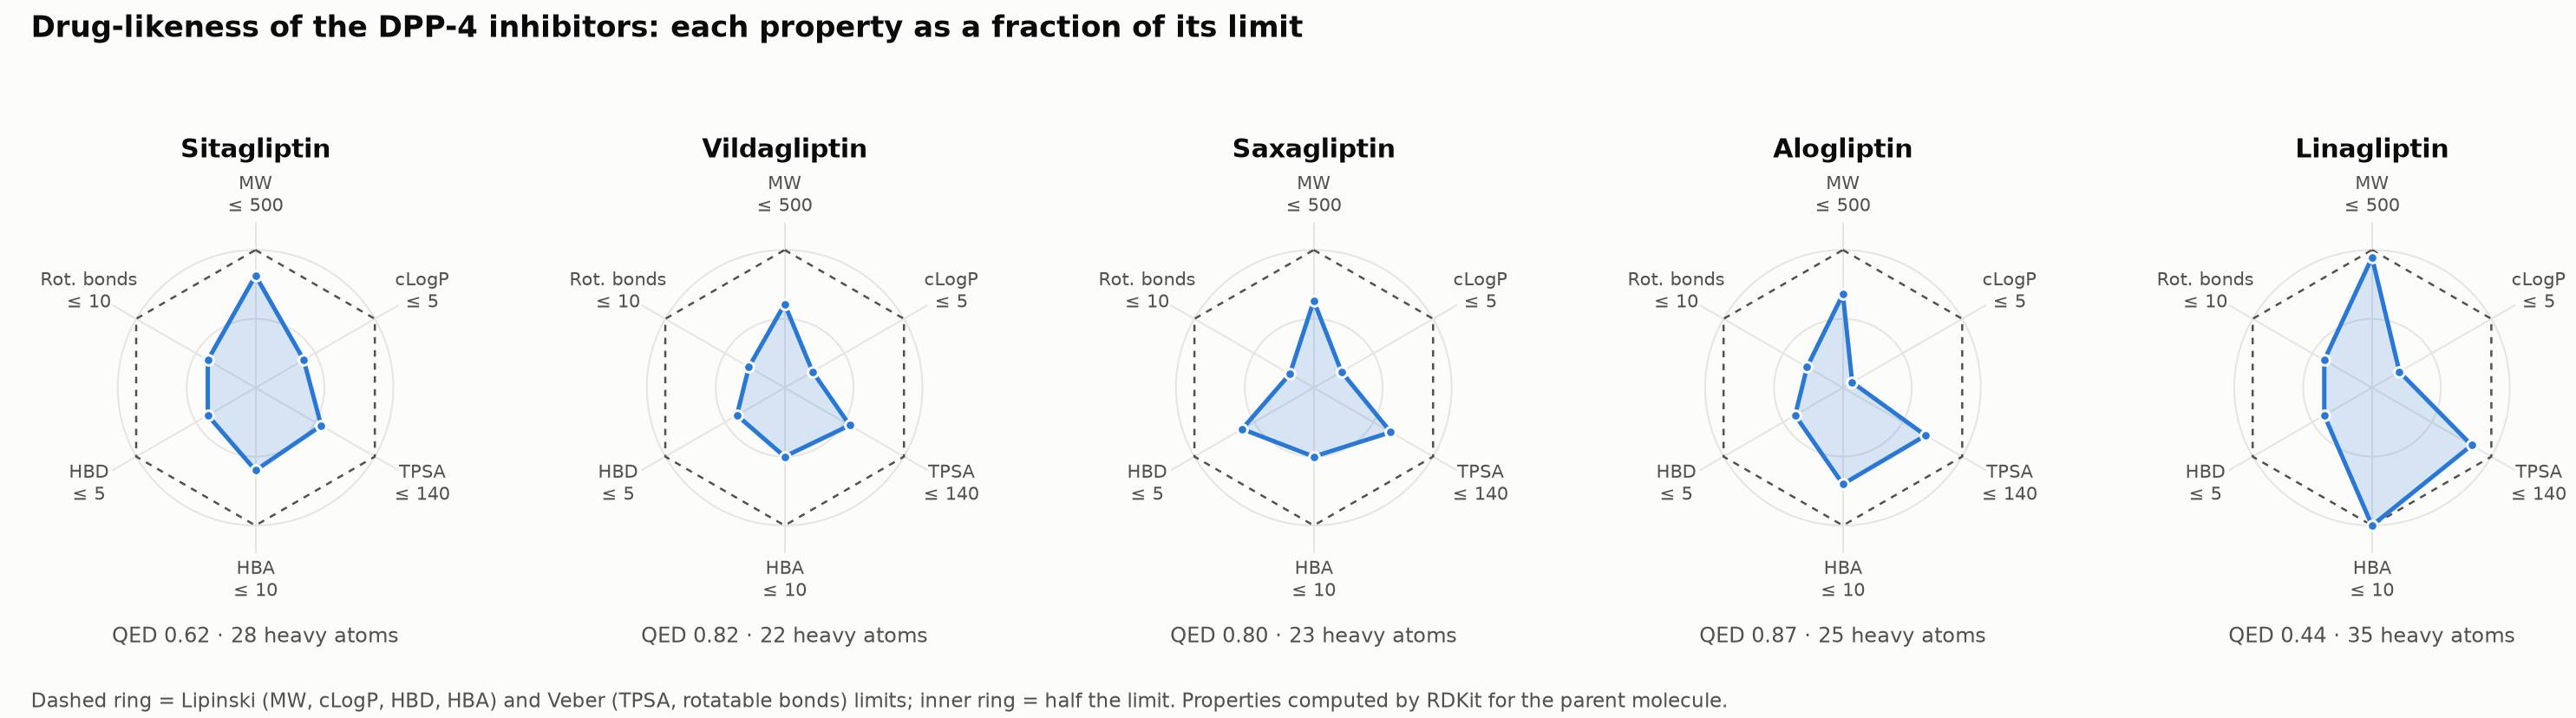

In [ ]:
# Code 1: Radar plots of the gliptins' properties as fractions of their limits
# The code is in plot_gliptin_radar.py, next to this notebook (73 lines).
from plot_gliptin_radar import *

plot_radar([replay.result(i) for i in (9, 10, 11, 12, 13)], ['Sitagliptin', 'Vildagliptin', 'Saxagliptin', 'Alogliptin', 'Linagliptin'])

**Figure 2: The gliptins: DPP-4 potency and selectivity over DPP-8 and DPP-9.** _(as recorded)_

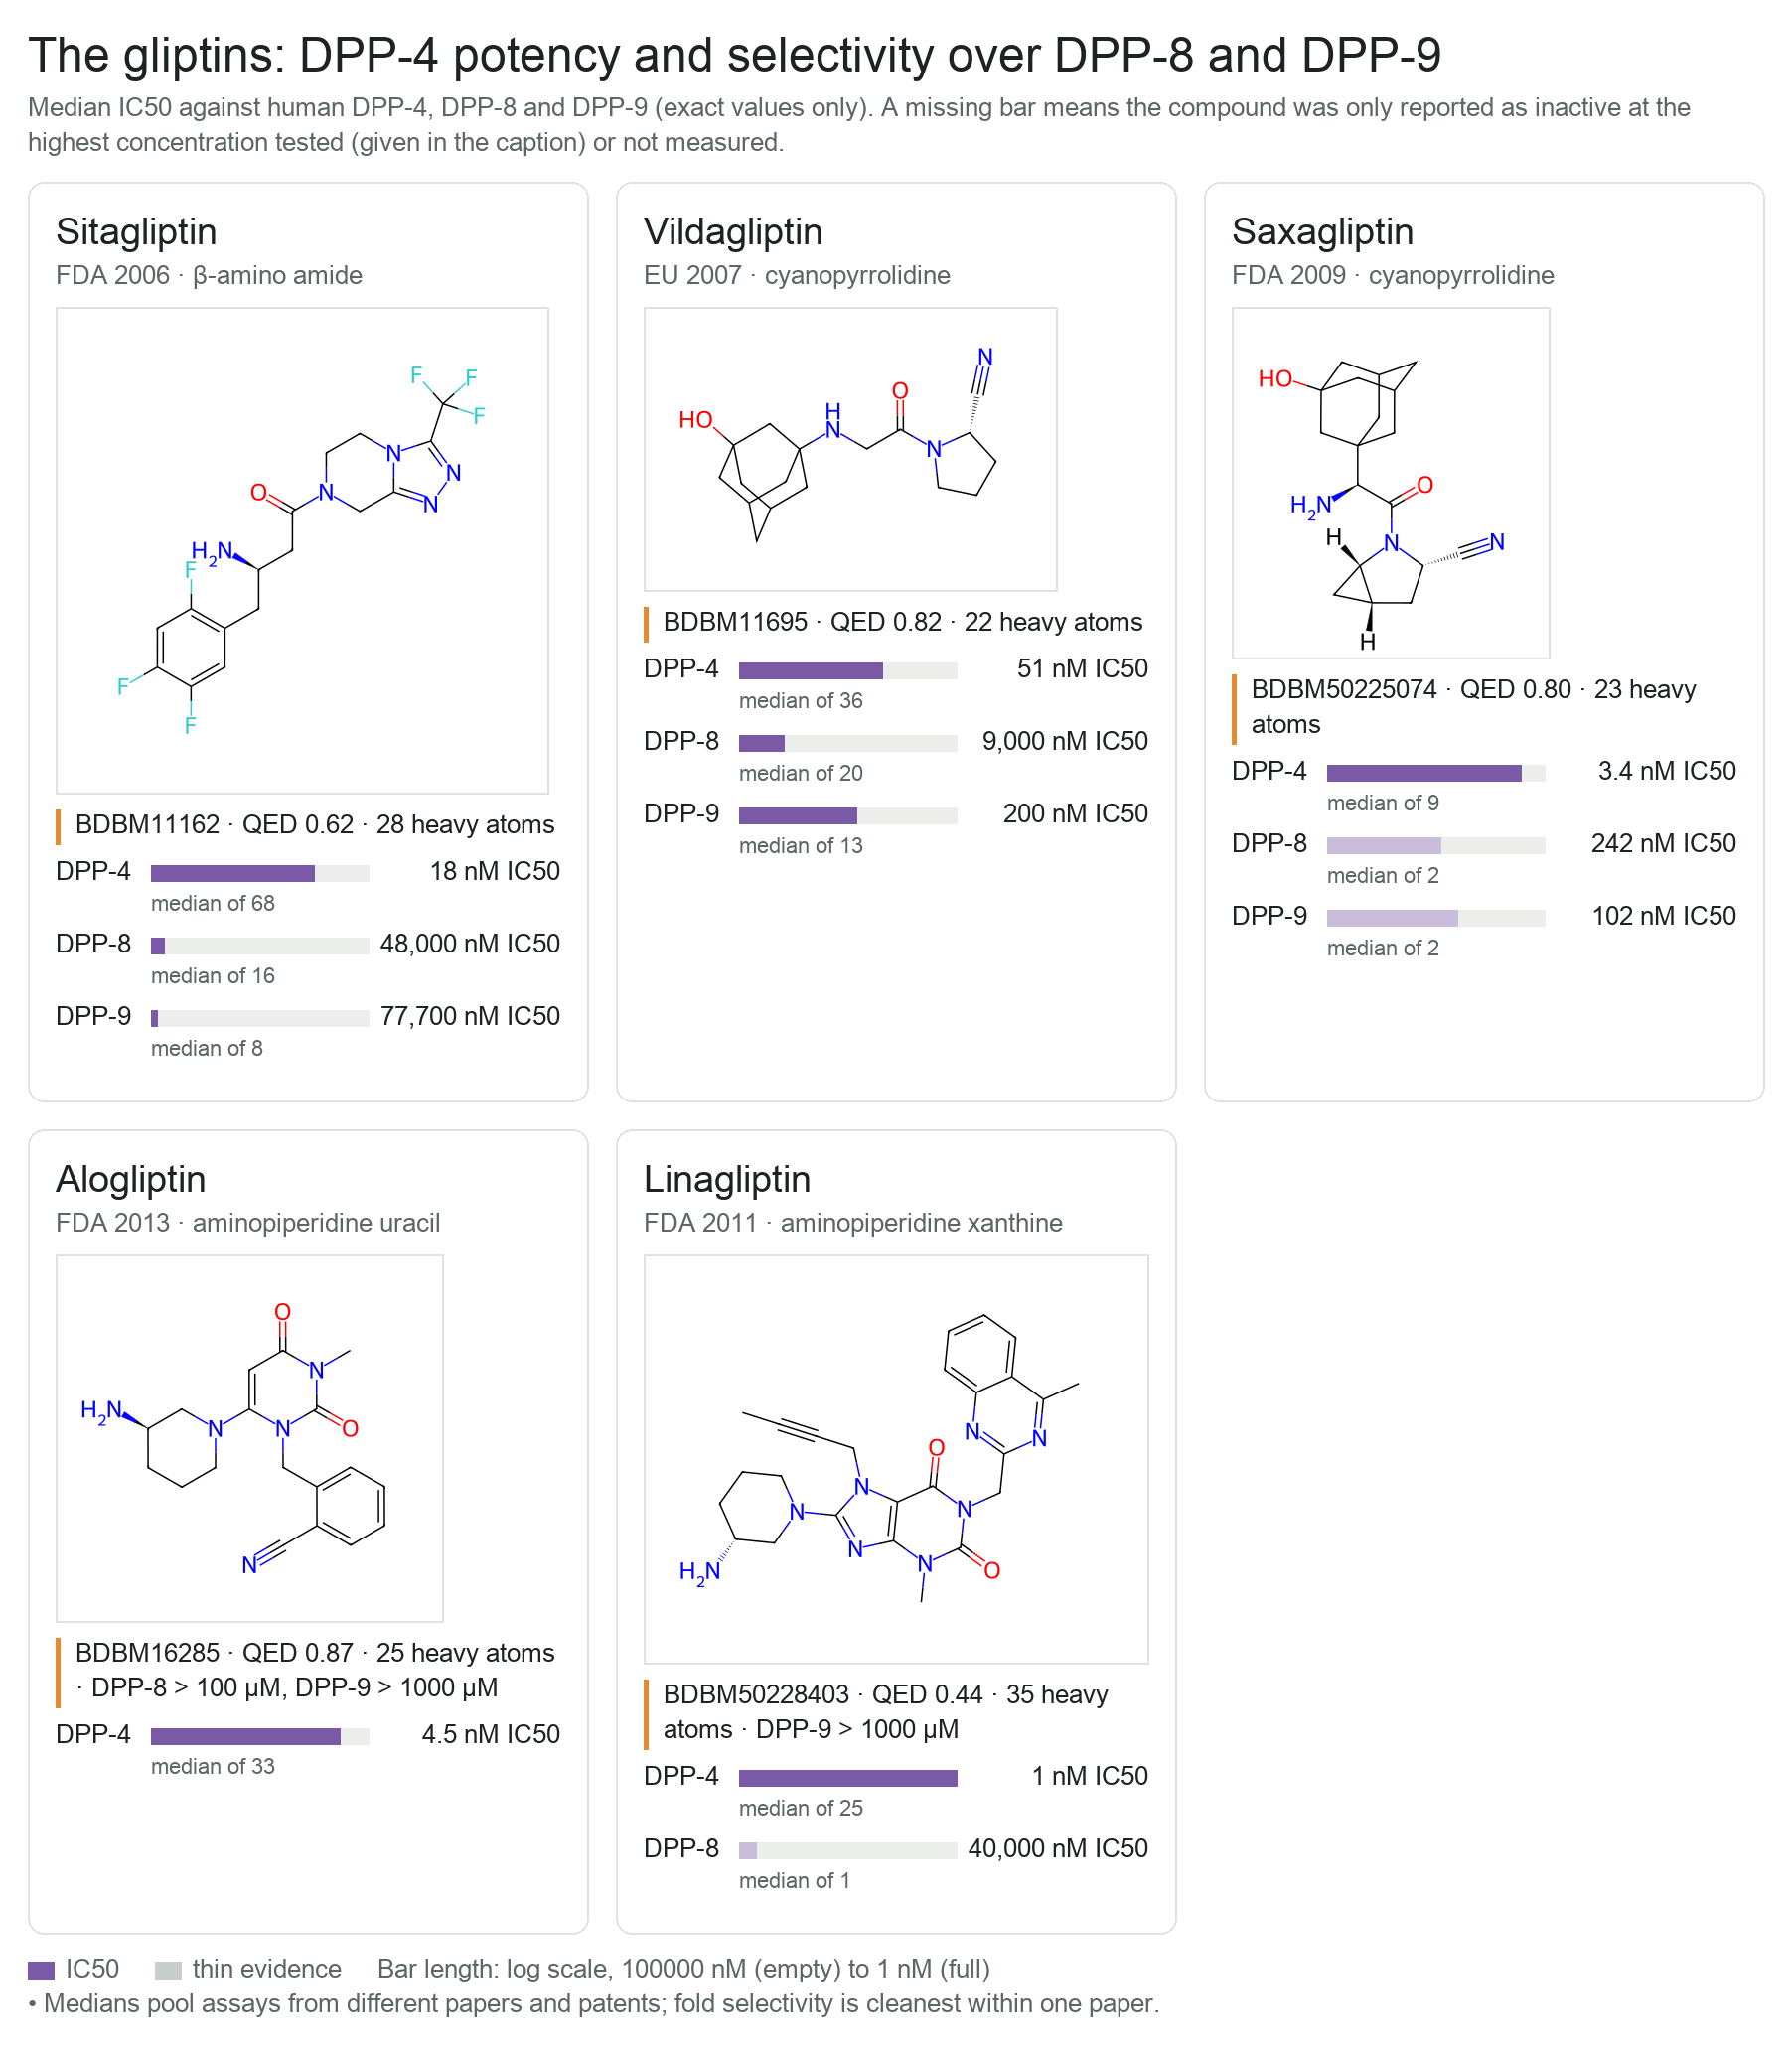

In [ ]:
# Figure 2 · draw_structure_grid draws it again
arguments = {
    'title': 'The gliptins: DPP-4 potency and selectivity over DPP-8 and DPP-9',
    'compounds': [
        {
            'smiles': 'N[C@@H](CC(=O)N1CCn2c(C1)nnc2C(F)(F)F)Cc1cc(F)c(F)cc1F',
            'title': 'Sitagliptin',
            'subtitle': 'FDA 2006 · β-amino amide',
            'caption': 'BDBM11162 · QED 0.62 · 28 heavy atoms',
            'bars': [
                {'label': 'DPP-4', 'value_nm': 18.0, 'type': 'IC50', 'note': 'median of 68'},
                {'label': 'DPP-8', 'value_nm': 48000.0, 'type': 'IC50', 'note': 'median of 16'},
                {'label': 'DPP-9', 'value_nm': 77705.0, 'type': 'IC50', 'note': 'median of 8'},
            ],
        },
        {
            'smiles': 'N#C[C@@H]1CCCN1C(=O)CNC12CC3CC(CC(O)(C3)C1)C2',
            'title': 'Vildagliptin',
            'subtitle': 'EU 2007 · cyanopyrrolidine',
            'caption': 'BDBM11695 · QED 0.82 · 22 heavy atoms',
            'bars': [
                {'label': 'DPP-4', 'value_nm': 51.0, 'type': 'IC50', 'note': 'median of 36'},
                {'label': 'DPP-8', 'value_nm': 9000.0, 'type': 'IC50', 'note': 'median of 20'},
                {'label': 'DPP-9', 'value_nm': 200.0, 'type': 'IC50', 'note': 'median of 13'},
            ],
        },
        {
            'smiles': 'N#C[C@@H]1C[C@@H]2C[C@@H]2N1C(=O)[C@@H](N)C12CC3CC(CC(O)(C3)C1)C2',
            'title': 'Saxagliptin',
            'subtitle': 'FDA 2009 · cyanopyrrolidine',
            'caption': 'BDBM50225074 · QED 0.80 · 23 heavy atoms',
            'bars': [
                {'label': 'DPP-4', 'value_nm': 3.4, 'type': 'IC50', 'note': 'median of 9'},
                {
                    'label': 'DPP-8',
                    'value_nm': 242.0,
                    'type': 'IC50',
                    'note': 'median of 2',
                    'faint': True,
                },
                {
                    'label': 'DPP-9',
                    'value_nm': 102.0,
                    'type': 'IC50',
                    'note': 'median of 2',
                    'faint': True,
                },
            ],
        },
        {
            'smiles': 'Cn1c(=O)cc(N2CCC[C@@H](N)C2)n(Cc2ccccc2C#N)c1=O',
            'title': 'Alogliptin',
            'subtitle': 'FDA 2013 · aminopiperidine uracil',
            'caption': 'BDBM16285 · QED 0.87 · 25 heavy atoms · DPP-8 > 100 µM, DPP-9 > 1000 µM',
            'bars': [{'label': 'DPP-4', 'value_nm': 4.5, 'type': 'IC50', 'note': 'median of 33'}],
        },
        {
            'smiles': 'CC#CCn1c(nc2n(C)c(=O)n(Cc3nc(C)c4ccccc4n3)c(=O)c12)N1CCC[C@@H](N)C1',
            'title': 'Linagliptin',
            'subtitle': 'FDA 2011 · aminopiperidine xanthine',
            'caption': 'BDBM50228403 · QED 0.44 · 35 heavy atoms · DPP-9 > 1000 µM',
            'bars': [
                {'label': 'DPP-4', 'value_nm': 1.0, 'type': 'IC50', 'note': 'median of 25'},
                {
                    'label': 'DPP-8',
                    'value_nm': 40000.0,
                    'type': 'IC50',
                    'note': 'median of 1',
                    'faint': True,
                },
            ],
        },
    ],
    'columns': 3,
    'description': 'Median IC50 against human DPP-4, DPP-8 and DPP-9 (exact values only). A missing bar means the compound was only reported as inactive at the highest concentration tested (given in the caption) or not measured.',
    'notes': [
        'Medians pool assays from different papers and patents; fold selectivity is cleanest within one paper.',
    ],
    'min_core_atoms': 8,
    'min_core_share': 0.8,
}
await replay.figure(2, 'draw_structure_grid', arguments)

**🧠 Assistant**

All five gliptins are comfortably drug-like: none breaks a Lipinski or Veber rule, and every shape in the radar plots (Figure 1) stays inside the dashed limit ring. Where they differ is size and polarity, and, more importantly for these drugs, selectivity over the related enzymes DPP-8 and DPP-9 (Figure 2).

**What the radar plots show**

**Vildagliptin, saxagliptin and alogliptin are the small ones** (22–25 heavy atoms, MW 303–339) and have the highest QED scores (0.80–0.87; QED combines eight properties into a 0–1 drug-likeness score). Vildagliptin and saxagliptin have no aromatic ring at all: their adamantane and cyanopyrrolidine make them almost entirely sp3 (Fsp3 0.88–0.89).

**Linagliptin is the outlier.** It is the largest (35 heavy atoms, MW 473) and the most polar (TPSA 117 Å²), and it uses all 10 hydrogen-bond acceptors Lipinski allows, so its HBA spoke touches the limit ring. Its QED is the lowest, 0.44.

**cLogP is low for every gliptin** (0.4 for alogliptin to 2.0 for sitagliptin). All five carry a basic amine, which binds the two glutamates in the DPP-4 active site.

**Structural alerts.** None matches a PAINS filter. The Brenk filters flag sitagliptin's trifluorophenyl ring (halogenated_ring_1) and linagliptin's butynyl group (triple_bond). These are medicinal-chemistry warnings, not verdicts: both are approved drugs.

**Potency and selectivity (Figure 2)**

All five are potent DPP-4 inhibitors, from a median IC50 of 1 nM (linagliptin) to 51 nM (vildagliptin). They split into two groups on selectivity:

- **Sitagliptin, alogliptin and linagliptin barely touch DPP-8 and DPP-9.** Sitagliptin's median IC50s there are about 48 and 78 µM. Alogliptin was reported only as inactive at the highest concentration tested (12 measurements on each enzyme), so it has no bars for them; linagliptin has a single exact DPP-8 value (40 µM) and was inactive in the DPP-9 assays (3 measurements, above 1000 µM).
- **The two cyanopyrrolidines, vildagliptin and saxagliptin, are much less selective, especially against DPP-9.** Vildagliptin's DPP-9 median of 200 nM is only about 4-fold weaker than its DPP-4 median. Saxagliptin's DPP-8 and DPP-9 values rest on two measurements each. Inhibiting DPP-8 and DPP-9 was linked to toxicity in animal studies, which is why selectivity over them became a design goal for the later gliptins.

**The structures share no common core.** The gliptins are three chemotypes that reach the same pocket: a β-amino amide (sitagliptin), two cyanopyrrolidines (vildagliptin, saxagliptin) and two aminopiperidines on different heterocycles (alogliptin, linagliptin). Their largest common substructure is 3 atoms, below the 8-atom minimum for a shared core, so Figure 2 draws each structure on its own, unaligned, with no core highlighted.

**A lesson about drug-likeness scores.** The rules filter out compounds that are unlikely to become oral drugs; they do not rank compounds that pass. All five gliptins pass, and the property that separates them here, selectivity within the enzyme family, is something only the binding data can show. A low QED did not stop linagliptin either.

**A lesson about finding a drug by name.** BindingDB records vildagliptin's main entry under its development code, NVP-LAF237 (BDBM11695, 121 measurements). A name search for "vildagliptin" finds only minor records. chemical_name_to_smiles resolved the name to a structure through PubChem and matched it to the main entry by InChIKey.

**How this was answered**

- chemical_name_to_smiles turned each gliptin name into its BindingDB entry.
- search_targets found human DPP-4 (target 1234), DPP-8 (1236) and DPP-9 (1237).
- get_compound returned each gliptin's properties, scaffold and structural alerts. These come from the compound_property table, which RDKit computed from each compound's structure (salts removed).
- A run_sql query took the median exact IC50 for each gliptin on each of the three enzymes and counted the measurements reported only as inactive.
- The radar plots were drawn with matplotlib (plot_gliptin_radar.py, from gliptin_properties.csv) and added with add_figure. Each axis is the property divided by its limit, so all six axes share one scale. draw_structure_grid drew the structures with the IC50 bars.

**Try next**

- "Which DPP-4 inhibitors with an IC50 below 10 nM have a QED of at least 0.8?" (find_ligands_for_target with properties: {min_qed: 0.8})
- "Make the same radar plots for the SGLT2 inhibitors (the gliflozins)."
- Example 7.2 uses heavy-atom counts to follow ligand efficiency over time.

## Verification

How each rerun call compared with its recorded result.

In [ ]:
replay.summary()

_Recorded: 14 tool calls, 1 figure to redraw. Run all cells to compare._

## How to cite

Cite this notebook (for example deposited with a DOI) together with the data and software it ran on:

- Data: BindingDB release 202611, https://www.bindingdb.org/rwd/bind/BDB-mySQL_All_202611_dmp.zip (SHA-256 daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381)
- Software: mcp-bindingdb v0.1.17, commit 79dae5d22c0f15b8ded9b49adc8b105f0463703a, https://github.com/sbl-sdsc/mcp-bindingdb
- Analysis: Example 7.1 — Drug-likeness radar: the DPP-4 inhibitors, 2026-11-23, with claude-sonnet-5-5
- BindingDB: Liu T, Hwang L, Burley SK, Nitsche CI, Southan C, Walters WP, Gilson MK. BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data. Nucleic Acids Research 53(D1):D1633-D1644, 2025. https://doi.org/10.1093/nar/gkae1075

As BibTeX, for this server, BindingDB and RDKit (used for structure search, properties and drawings):

```bibtex
@software{rose2026mcp-bindingdb,
  title={MCP BindingDB Server},
  author={Rose, P.W.},
  year={2026},
  url={https://github.com/sbl-sdsc/mcp-bindingdb}
}

@article{liu2025bindingdb,
  title={BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data},
  author={Liu, T. and Hwang, L. and Burley, S.K. and Nitsche, C.I. and Southan, C. and Walters, W.P. and Gilson, M.K.},
  journal={Nucleic Acids Research},
  volume={53},
  number={D1},
  pages={D1633--D1644},
  year={2025},
  doi={10.1093/nar/gkae1075}
}

@software{rdkit,
  title={RDKit: Open-source cheminformatics},
  author={Landrum, G. and others},
  version={2026.03.6},
  url={https://www.rdkit.org},
  doi={10.5281/zenodo.591637}
}
```